# SwiftLog Week 5: Machine Learning Engineering

**Mission:** Intelligent Logistics Prediction & Supply Chain Optimization.

This notebook reviews source data, engineered features, model comparisons, evaluation artefacts, and limitations. The full model-training pipeline is `../run_swiftlog_project.py`. Run that script from the project root to regenerate the saved models and outputs before rerunning this notebook.

The supplied data is used as provided for this educational prototype. Results are reported as measured; weak performance is not hidden or described as production-ready.

## 1. Imports and paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('..').resolve()
DATA = ROOT / 'Data'
PROCESSED = DATA / 'Processed_Datasets'
MODELS = ROOT / 'Models'


## 2. Source data and quality checks
The source tables cover customers, orders, order items, products, shipments, delivery performance, returns, inventory, warehouses, suppliers, and employees. The original file-level data dictionary is brief; calculated model features are documented in `Feature_Data_Dictionary.csv`.

In [2]:
quality = pd.read_csv(PROCESSED / 'data_quality_summary.csv')
display(quality)

,Dataset,Rows,Columns,Duplicate rows,Missing cells,Missing columns
0,Customers,1000,3,0,0,NaN
1,Delivery_Performance,5000,3,0,0,NaN
2,Employees,200,2,0,0,NaN
3,Inventory,4000,3,3,0,NaN
4,Orders,5000,4,0,0,NaN
5,Order_Items,15000,4,0,0,NaN
6,Products,250,3,0,0,NaN
7,Returns,500,3,0,0,NaN
8,Shipments,5000,4,0,0,NaN
9,Suppliers,150,2,0,0,NaN


## 3. Inspect the original target distributions

In [3]:
shipments = pd.read_csv(DATA / 'Original_Datasets' / 'SwiftLog_Shipments.csv')
returns = pd.read_csv(DATA / 'Original_Datasets' / 'SwiftLog_Returns.csv')
orders = pd.read_csv(DATA / 'Original_Datasets' / 'SwiftLog_Orders.csv')
print('Shipments:', len(shipments))
print('Delayed shipments (DelayDays > 0):', int((pd.to_numeric(shipments['DelayDays'], errors='coerce') > 0).sum()))
print('Orders associated with recorded returns:', returns['OrderID'].nunique())
print('Orders:', orders['OrderID'].nunique())

Shipments: 5000
Delayed shipments (DelayDays > 0): 4389
Orders associated with recorded returns: 473
Orders: 5000


## 4. Engineered feature samples
The delivery-delay target is `DelayDays > 0`. The return target is whether an order appears in the Returns table. Demand features use weekly product quantities and lagged values from prior weeks. Customer value is framed as next-month revenue, using the preceding three months of activity. For the demand and customer-value tasks, evaluation is chronological rather than a random row split.

### Delivery delay features

In [4]:
features = pd.read_csv(PROCESSED / 'delivery_delay_features.csv')
print('Shape:', features.shape)
display(features.head())

Shape: (5000, 8)


,WarehouseID,Location,City,OrderDate_Year,OrderDate_Month,OrderDate_Day,OrderDate_Weekday,Target_Delayed
0,W10,Kano,Ibadan,2026,7,22,2,0
1,W03,Abuja,Lagos,2026,4,11,5,1
2,W07,Lagos,Lagos,2026,1,7,2,0
3,W05,Lagos,Abuja,2026,1,30,4,0
4,W06,Lagos,Kano,2026,5,16,5,1


### Product return features

In [5]:
features = pd.read_csv(PROCESSED / 'product_return_features.csv')
print('Shape:', features.shape)
display(features.head())

Shape: (5000, 11)


,City,OrderDate_Year,OrderDate_Month,OrderDate_Day,OrderDate_Weekday,ItemCount,TotalQuantity,DistinctProducts,TotalRevenue,MeanUnitPrice,Target_Returned
0,Ibadan,2026,7,22,2,7.0,34.0,7.0,8273.72,221.988571,0
1,Lagos,2026,4,11,5,5.0,35.0,5.0,7330.27,225.812000,0
2,Lagos,2026,1,7,2,3.0,19.0,3.0,4713.13,296.120000,0
3,Abuja,2026,1,30,4,3.0,18.0,3.0,5903.11,329.630000,0
4,Kano,2026,5,16,5,3.0,16.0,3.0,3026.48,221.593333,0


### Weekly demand forecasting features

In [6]:
features = pd.read_csv(PROCESSED / 'demand_forecasting_features.csv')
print('Shape:', features.shape)
display(features.head())

Shape: (8250, 11)


,ProductID,Category,UnitPrice,Year,Month,DayOfWeek,Lag_1_Week,Lag_4_Weeks,Rolling_Mean_4_Weeks,DemandQuantity,WeekStart
0,P001,Electronics,248.85,2026,1,0,0.0,9.0,11.50,11.0,2026-01-26
1,P002,Fashion,177.08,2026,1,0,36.0,0.0,11.25,9.0,2026-01-26
2,P003,Food,358.11,2026,1,0,0.0,4.0,5.00,21.0,2026-01-26
3,P004,Electronics,487.85,2026,1,0,8.0,4.0,5.75,0.0,2026-01-26
4,P005,Electronics,20.62,2026,1,0,3.0,15.0,6.50,0.0,2026-01-26


### Customer next-month value features

In [7]:
features = pd.read_csv(PROCESSED / 'customer_value_features.csv')
print('Shape:', features.shape)
display(features.head())

Shape: (6000, 13)


,CustomerID,MonthStart,MonthRevenue,MonthQuantity,MonthItems,MonthAvgUnitPrice,MonthOrders,Previous_3M_Revenue,Previous_3M_Order_Count,Previous_3M_Quantity,Previous_3M_Item_Count,Previous_3M_Avg_Unit_Price,City
0,C0001,2026-04-01,0.0,0.0,0.0,NaN,0.0,1269.29,2.0,3.0,2.0,NaN,Abuja
1,C0002,2026-04-01,0.0,0.0,0.0,NaN,0.0,6624.25,2.0,23.0,5.0,NaN,Lagos
2,C0003,2026-04-01,0.0,0.0,0.0,NaN,0.0,0.00,1.0,0.0,0.0,NaN,Ibadan
3,C0004,2026-04-01,0.0,0.0,0.0,NaN,0.0,4898.25,1.0,20.0,3.0,NaN,Lagos
4,C0005,2026-04-01,0.0,0.0,0.0,NaN,0.0,559.82,2.0,4.0,2.0,NaN,Kano


## 5. Compare the candidate algorithms
The table contains three algorithms per task. `Selected` marks the model stored in `Best_Model.pkl`; `Tuned` indicates that a tuning search was accepted. The selected model metrics are updated in the comparison table to match the saved model.

In [8]:
comparison = pd.read_excel(MODELS / 'Model_Comparison.xlsx')
display(comparison)

,Problem,Algorithm,Rows,Features,Selected,Tuned,Accuracy,Precision,Recall,F1,ROC_AUC,MAE,RMSE,R2
0,Delivery Delay Classification,Random Forest (tuned),5000,7,True,True,0.829,0.882990,0.928246,0.905053,0.511894,NaN,NaN,NaN
1,Delivery Delay Classification,Decision Tree,5000,7,False,False,0.542,0.876344,0.556948,0.681058,0.486645,NaN,NaN,NaN
2,Delivery Delay Classification,Logistic Regression,5000,7,False,False,0.523,0.871985,0.535308,0.663373,0.475447,NaN,NaN,NaN
3,Product Return Classification,Logistic Regression,5000,10,True,False,0.538,0.098468,0.473684,0.163043,0.487595,NaN,NaN,NaN
4,Product Return Classification,Decision Tree,5000,10,False,False,0.421,0.085616,0.526316,0.147275,0.475731,NaN,NaN,NaN
5,Product Return Classification,Random Forest,5000,10,False,False,0.880,0.096774,0.031579,0.047619,0.508962,NaN,NaN,NaN
6,Product Demand Forecasting,Random Forest Regressor (tuned),8250,9,True,True,NaN,NaN,NaN,NaN,NaN,6.523835,8.077778,-0.013980
7,Product Demand Forecasting,Decision Tree Regressor,8250,9,False,False,NaN,NaN,NaN,NaN,NaN,6.657536,8.485197,-0.118843
8,Product Demand Forecasting,Linear Regression,8250,9,False,False,NaN,NaN,NaN,NaN,NaN,6.612885,8.205115,-0.046200
9,Customer Value Prediction (Next Month),Linear Regression,6000,6,True,False,NaN,NaN,NaN,NaN,NaN,2990.706373,3757.004105,-0.068606


## 6. Review selected models and held-out metrics

In [9]:
selected = comparison[comparison['Selected'] == True]
display(selected)

,Problem,Algorithm,Rows,Features,Selected,Tuned,Accuracy,Precision,Recall,F1,ROC_AUC,MAE,RMSE,R2
0,Delivery Delay Classification,Random Forest (tuned),5000,7,True,True,0.829,0.882990,0.928246,0.905053,0.511894,NaN,NaN,NaN
3,Product Return Classification,Logistic Regression,5000,10,True,False,0.538,0.098468,0.473684,0.163043,0.487595,NaN,NaN,NaN
6,Product Demand Forecasting,Random Forest Regressor (tuned),8250,9,True,True,NaN,NaN,NaN,NaN,NaN,6.523835,8.077778,-0.013980
9,Customer Value Prediction (Next Month),Linear Regression,6000,6,True,False,NaN,NaN,NaN,NaN,NaN,2990.706373,3757.004105,-0.068606


## 7. Evaluation visuals

delivery_delay_classification_confusion_matrix.png


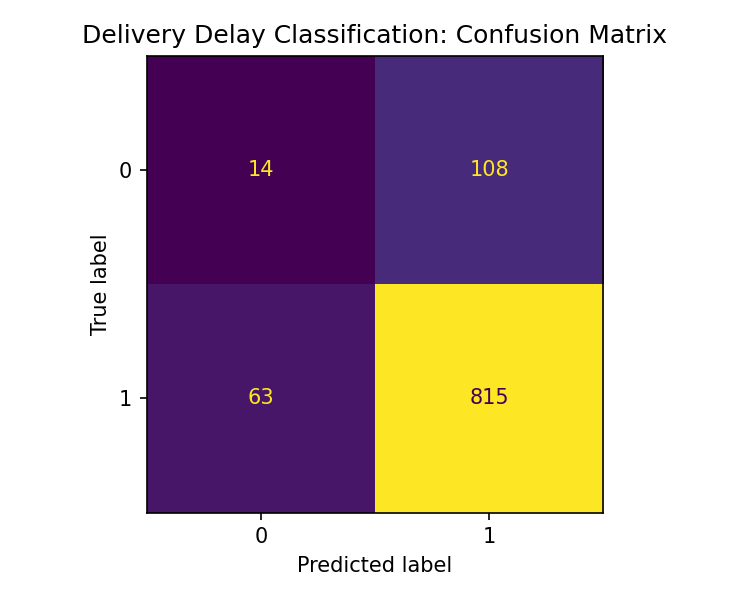

product_return_classification_confusion_matrix.png


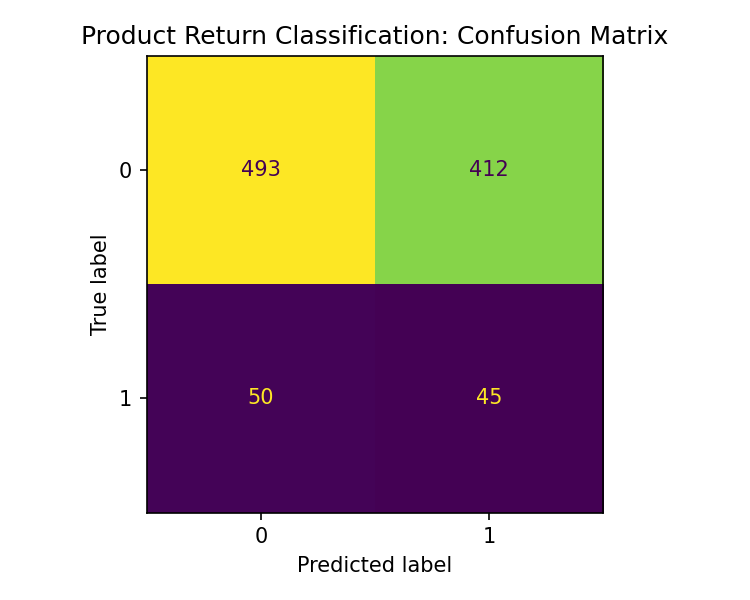

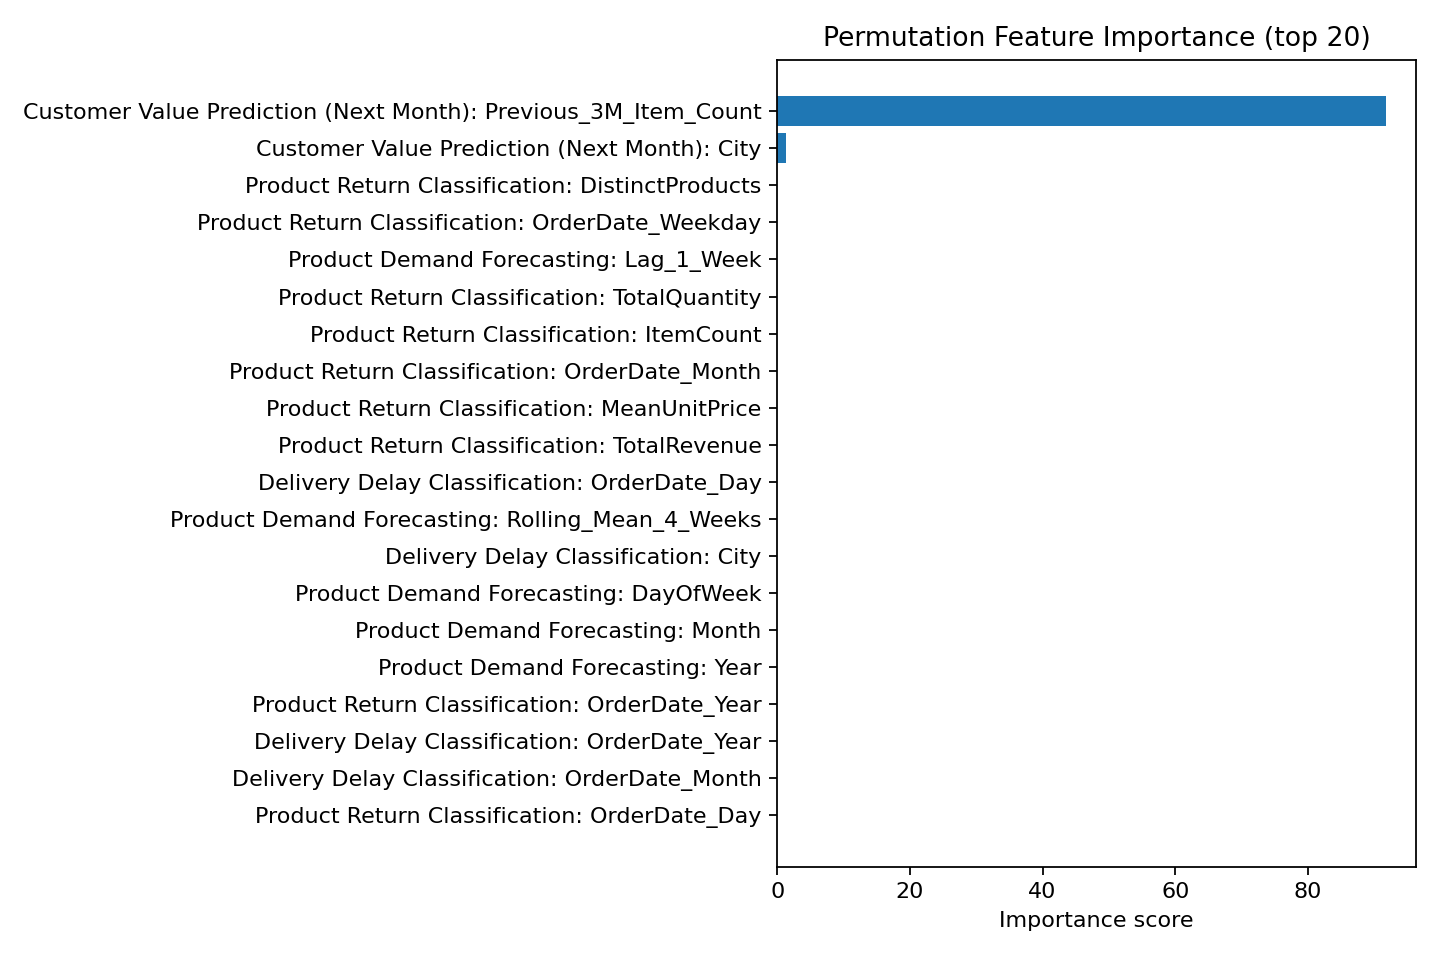

In [10]:
from IPython.display import Image, display
for name in ['delivery_delay_classification_confusion_matrix.png', 'product_return_classification_confusion_matrix.png']:
    path = MODELS / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))
importance = MODELS / 'Feature_Importance.png'
if importance.exists():
    display(Image(filename=str(importance)))

## 8. Interpretation and limitations

- Delivery delay and return classification ROC-AUC values near 0.5 indicate weak class discrimination, even when F1 or accuracy appears high. This is especially important for the imbalanced delay target.
- Negative held-out R-squared for demand or next-month customer value means the selected model performed worse than a simple mean-prediction baseline on the test period.
- The dataset spans a limited period and has limited operational context. Forecast quality may improve with richer timestamps, planned delivery dates, inventory snapshots, and more history.
- Model outputs should support human review only. They are not validated for live logistics decisions.

## 9. Reproduce the outputs

From the project root, run `python run_swiftlog_project.py`. The script preprocesses the source data, builds the features, compares three algorithms for each task, evaluates candidates, saves model bundles and visualizations, and regenerates reports and the presentation. Then rerun this notebook to inspect the refreshed outputs.